In [2]:
from google.colab import files
uploaded = files.upload()

Saving ecommerce_dirty_50_records.csv to ecommerce_dirty_50_records.csv


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("ecommerce_dirty_50_records.csv")

In [4]:
#Inspect he data
df.head()

,Order_ID,Product,Category,Unit_Price,Quantity,Order_Date,City,Customer_ID
0,ORD1001,laptop,electronics,55000,1,2026-01-01,chennai,CUST01
1,ORD1002,Smartphone,Electronics,25000,2,2026-01-02,BANGALORE,CUST02
2,ORD1003,HEADPHONES,AUDIO,1500,3,2026-01-03,Chennai,CUST03
3,ORD1004,Keyboard,Accessories,"1,200",2,2026-01-04,Hyderabad,CUST04
4,ORD1005,mouse,Accessories,500,5,2026-01-05,Mumbai,CUST05


In [5]:
#Check the dimensions
df.shape

(51, 8)

In [6]:
#cols and their types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51 entries, 0 to 50
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Order_ID     51 non-null     object
 1   Product      50 non-null     object
 2   Category     51 non-null     object
 3   Unit_Price   51 non-null     object
 4   Quantity     51 non-null     object
 5   Order_Date   50 non-null     object
 6   City         50 non-null     object
 7   Customer_ID  51 non-null     object
dtypes: object(8)
memory usage: 3.3+ KB


In [7]:
#check the missing values
df.isnull().sum()

,0
Order_ID,0
Product,1
Category,0
Unit_Price,0
Quantity,0
Order_Date,1
City,1
Customer_ID,0


In [8]:
#Handle missing values
df["Product"] = df["Product"].fillna("Unknown")
df["City"] = df["City"].fillna("Unknown")

df["Unit_Price"] = pd.to_numeric(
    df["Unit_Price"].astype(str).str.replace(",", "", regex=False),
    errors="coerce"
)

df["Quantity"] = pd.to_numeric(
    df["Quantity"],
    errors="coerce"
)

df["Unit_Price"] = df["Unit_Price"].fillna(
    df["Unit_Price"][df["Unit_Price"] > 0].median()
)

df["Quantity"] = df["Quantity"].fillna(
    df["Quantity"][df["Quantity"] > 0].median()
)

In [9]:
#Identify duplicates
df.duplicated().sum()

np.int64(1)

In [11]:
#drop duplicates
df = df.drop_duplicates()

In [12]:
df

,Order_ID,Product,Category,Unit_Price,Quantity,Order_Date,City,Customer_ID
0,ORD1001,laptop,electronics,55000.0,1.0,2026-01-01,chennai,CUST01
1,ORD1002,Smartphone,Electronics,25000.0,2.0,2026-01-02,BANGALORE,CUST02
2,ORD1003,HEADPHONES,AUDIO,1500.0,3.0,2026-01-03,Chennai,CUST03
3,ORD1004,Keyboard,Accessories,1200.0,2.0,2026-01-04,Hyderabad,CUST04
4,ORD1005,mouse,Accessories,500.0,5.0,2026-01-05,Mumbai,CUST05
5,ORD1006,Laptop,Electronics,55000.0,1.0,2026-01-06,chennai,CUST06
6,ORD1007,Monitor,electronics,18000.0,2.0,2026-01-07,Delhi,CUST07
7,ORD1008,smartphone,Electronics,25000.0,1.0,2026-01-08,Bangalore,CUST08
8,ORD1009,Unknown,Audio,1500.0,4.0,2026-01-09,Mumbai,CUST09
9,ORD1010,Keyboard,Accessories,1200.0,3.0,2026-01-10,Unknown,CUST10


In [13]:
#standardize text
df["Product"] = df["Product"].str.strip().str.title()
df["Category"] = df["Category"].str.strip().str.title()
df["City"] = df["City"].str.strip().str.title()

In [14]:
#convert dates
df["Order_Date"] = pd.to_datetime(
    df["Order_Date"],
    format="mixed",
    dayfirst=True,
    errors="coerce"
)

In [15]:
#Convert numerical values
df["Unit_Price"] = pd.to_numeric(df["Unit_Price"], errors="coerce")
df["Quantity"] = pd.to_numeric(df["Quantity"], errors="coerce")

In [16]:
df

,Order_ID,Product,Category,Unit_Price,Quantity,Order_Date,City,Customer_ID
0,ORD1001,Laptop,Electronics,55000.0,1.0,2026-01-01,Chennai,CUST01
1,ORD1002,Smartphone,Electronics,25000.0,2.0,2026-01-02,Bangalore,CUST02
2,ORD1003,Headphones,Audio,1500.0,3.0,2026-01-03,Chennai,CUST03
3,ORD1004,Keyboard,Accessories,1200.0,2.0,2026-01-04,Hyderabad,CUST04
4,ORD1005,Mouse,Accessories,500.0,5.0,2026-01-05,Mumbai,CUST05
5,ORD1006,Laptop,Electronics,55000.0,1.0,2026-01-06,Chennai,CUST06
6,ORD1007,Monitor,Electronics,18000.0,2.0,2026-01-07,Delhi,CUST07
7,ORD1008,Smartphone,Electronics,25000.0,1.0,2026-01-08,Bangalore,CUST08
8,ORD1009,Unknown,Audio,1500.0,4.0,2026-01-09,Mumbai,CUST09
9,ORD1010,Keyboard,Accessories,1200.0,3.0,2026-01-10,Unknown,CUST10


In [17]:
#Identify outliers — IQR method
Q1 = df["Unit_Price"].quantile(0.25)
Q3 = df["Unit_Price"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[
    (df["Unit_Price"] < lower_bound) |
    (df["Unit_Price"] > upper_bound)
]

outliers

,Order_ID,Product,Category,Unit_Price,Quantity,Order_Date,City,Customer_ID
42,ORD1043,Laptop,Electronics,9999999.0,1.0,2026-02-13,Mumbai,CUST43


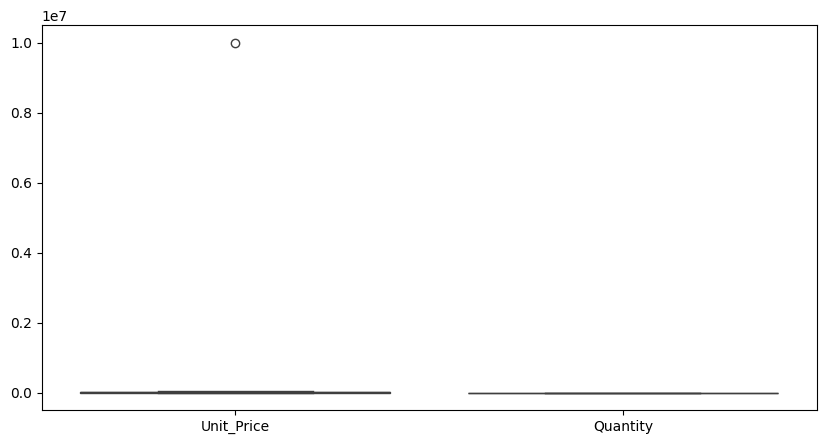

In [18]:
#Visualize outliers — box plots
plt.figure(figsize=(10, 5))
sns.boxplot(data=df[["Unit_Price", "Quantity"]])
plt.show()

In [19]:
#Create revenue and a derived feature
df["Revenue"] = df["Unit_Price"] * df["Quantity"]

In [20]:
def price_category(price):
    if price < 1000:
        return "Low"
    elif price <= 20000:
        return "Medium"
    else:
        return "High"

df["Price_Category"] = df["Unit_Price"].apply(price_category)

In [21]:
df

,Order_ID,Product,Category,Unit_Price,Quantity,Order_Date,City,Customer_ID,Revenue,Price_Category
0,ORD1001,Laptop,Electronics,55000.0,1.0,2026-01-01,Chennai,CUST01,55000.0,High
1,ORD1002,Smartphone,Electronics,25000.0,2.0,2026-01-02,Bangalore,CUST02,50000.0,High
2,ORD1003,Headphones,Audio,1500.0,3.0,2026-01-03,Chennai,CUST03,4500.0,Medium
3,ORD1004,Keyboard,Accessories,1200.0,2.0,2026-01-04,Hyderabad,CUST04,2400.0,Medium
4,ORD1005,Mouse,Accessories,500.0,5.0,2026-01-05,Mumbai,CUST05,2500.0,Low
5,ORD1006,Laptop,Electronics,55000.0,1.0,2026-01-06,Chennai,CUST06,55000.0,High
6,ORD1007,Monitor,Electronics,18000.0,2.0,2026-01-07,Delhi,CUST07,36000.0,Medium
7,ORD1008,Smartphone,Electronics,25000.0,1.0,2026-01-08,Bangalore,CUST08,25000.0,High
8,ORD1009,Unknown,Audio,1500.0,4.0,2026-01-09,Mumbai,CUST09,6000.0,Medium
9,ORD1010,Keyboard,Accessories,1200.0,3.0,2026-01-10,Unknown,CUST10,3600.0,Medium


In [22]:
#Save results
df.to_csv("cleaned_ecommerce_dataset.csv", index=False)